In [428]:
import pandas as pd

df = pd.read_csv('../../udslong_imputed.csv')

visit_counts = df['NACCID'].value_counts()

repeated_patients = visit_counts[visit_counts > 1]

print(f"Total rows (visits) in dataset: {len(df)}")
print(f"Total unique patients: {len(visit_counts)}")
print(f"Patients with repeated visits: {len(repeated_patients)}")
print(f"Percentage of patients with repeated visits: {(len(repeated_patients) / len(visit_counts)) * 100:.2f}%")

Total rows (visits) in dataset: 1237
Total unique patients: 1237
Patients with repeated visits: 0
Percentage of patients with repeated visits: 0.00%


In [429]:
import pandas as pd

df_clinical = pd.read_csv('../../udslong_imputed.csv')
df_mri = pd.read_csv('../../mriscanclean.csv')

categorical_vars = [
    'SEX', 'HYPERTEN', 'DIABETES', 'CBSTROKE', 'TOBAC100', 
    'DIABTYPE', 'NACCAPOE', 'NACCUDSD', 'CDRGLOB'
]

print("--- Categorical Variables Distribution (udslong_imputed) ---")
for col in categorical_vars:
    counts = df_clinical[col].value_counts(dropna=False)
    percs = df_clinical[col].value_counts(normalize=True, dropna=False) * 100
    summary_df = pd.DataFrame({'Frequency': counts, 'Percentage (%)': percs})
    print(f"\nDistribution for {col}:")
    display(summary_df.round(2))

quant_clinical_vars = ['NACCAGE', 'EDUC', 'CDRSUM', 'NACCBMI', 'NACCGDS', 'SMOKYRS']

quant_mri_vars = [
    'LH_ENTORHINAL_GVOL', 'RH_ENTORHINAL_GVOL', 
    'LH_PARAHIPPOCAMPAL_GVOL', 'RH_PARAHIPPOCAMPAL_GVOL',
    'LH_ENTORHINAL_AVGTH', 'RH_ENTORHINAL_AVGTH', 
    'LH_PARAHIPPOCAMPAL_AVGTH', 'RH_PARAHIPPOCAMPAL_AVGTH'
]

print("\n--- Quantitative Clinical Variables Summary (udslong_imputed) ---")
display(df_clinical[quant_clinical_vars].describe().round(2).T)

print("\n--- Structural MRI Variables Summary (mriscanclean) ---")
display(df_mri[quant_mri_vars].describe().round(2).T)

--- Categorical Variables Distribution (udslong_imputed) ---

Distribution for SEX:


,Frequency,Percentage (%)
SEX,,
2.0,740,59.82
1.0,497,40.18



Distribution for HYPERTEN:


,Frequency,Percentage (%)
HYPERTEN,,
0.0,731,59.09
1.0,444,35.89
2.0,29,2.34
9.0,11,0.89
0.6,7,0.57
0.2,7,0.57
0.4,5,0.40
2.4,1,0.08
0.8,1,0.08



Distribution for DIABETES:


,Frequency,Percentage (%)
DIABETES,,
0.0,1092,88.28
1.0,112,9.05
2.0,13,1.05
0.2,8,0.65
9.0,8,0.65
0.4,2,0.16
0.6,1,0.08
0.8,1,0.08


... (12 outputs left out)


--- Quantitative Clinical Variables Summary (udslong_imputed) ---


,count,mean,std,min,25%,50%,75%,max
NACCAGE,1237.0,68.19,8.04,41.0,63.0,68.0,74.0,91.0
EDUC,1237.0,16.39,4.29,0.0,14.0,16.0,18.0,99.0
CDRSUM,1237.0,0.82,1.72,0.0,0.0,0.0,1.0,15.0
NACCBMI,1237.0,117.03,261.98,15.6,24.1,27.3,32.2,888.8
NACCGDS,1237.0,2.01,5.90,0.0,0.0,1.0,2.0,88.0
SMOKYRS,1237.0,7.79,16.25,0.0,0.0,0.0,10.0,99.0



--- Structural MRI Variables Summary (mriscanclean) ---


,count,mean,std,min,25%,50%,75%,max
LH_ENTORHINAL_GVOL,1237.0,1554.28,413.52,0.00,1295.00,1545.00,1785.00,4265.00
RH_ENTORHINAL_GVOL,1237.0,1525.40,405.44,6.00,1289.00,1513.00,1748.00,5334.00
LH_PARAHIPPOCAMPAL_GVOL,1237.0,2036.71,387.89,167.00,1791.00,2019.00,2257.00,5136.00
RH_PARAHIPPOCAMPAL_GVOL,1237.0,1911.24,344.96,74.00,1718.00,1903.00,2090.00,6335.00
LH_ENTORHINAL_AVGTH,1237.0,2.97,0.38,0.88,2.76,3.02,3.23,3.98
RH_ENTORHINAL_AVGTH,1237.0,3.06,0.40,0.73,2.85,3.10,3.32,3.97
LH_PARAHIPPOCAMPAL_AVGTH,1237.0,2.59,0.28,1.43,2.41,2.59,2.80,3.46
RH_PARAHIPPOCAMPAL_AVGTH,1237.0,2.56,0.25,0.80,2.40,2.56,2.72,3.30


--- CDRSUM Distribution for Dementia Patients (NACCUDSD=4, N=131) ---


,Frequency,Percentage (%)
"(0.985, 2.4]",21,16.03
"(2.4, 3.8]",32,24.43
"(3.8, 5.2]",40,30.53
"(5.2, 6.6]",13,9.92
"(6.6, 8.0]",14,10.69
"(8.0, 9.4]",5,3.82
"(9.4, 10.8]",0,0.00
"(10.8, 12.2]",3,2.29
"(12.2, 13.6]",1,0.76
"(13.6, 15.0]",2,1.53


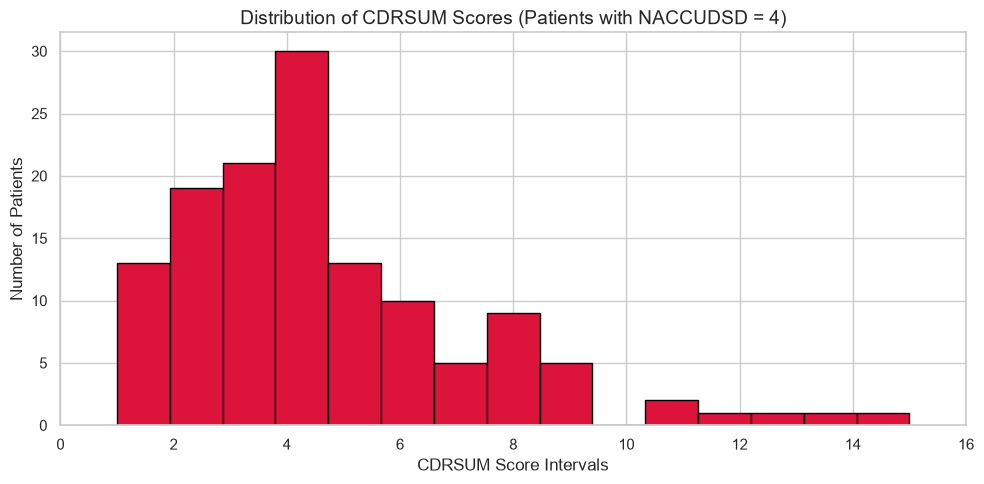

In [430]:
import pandas as pd
import matplotlib.pyplot as plt

df_dementia = df_clinical[df_clinical['NACCUDSD'] == 4.0]

print(f"--- CDRSUM Distribution for Dementia Patients (NACCUDSD=4, N={len(df_dementia)}) ---")
counts = df_dementia['CDRSUM'].value_counts(bins=10).sort_index()
percs = df_dementia['CDRSUM'].value_counts(bins=10, normalize=True).sort_index() * 100

summary_df = pd.DataFrame({'Frequency': counts, 'Percentage (%)': percs})
display(summary_df.round(2))

plt.figure(figsize=(10, 5))

plt.hist(
    df_dementia['CDRSUM'].dropna(), 
    bins=15,            
    color='crimson', 
    edgecolor='black'
)

plt.title('Distribution of CDRSUM Scores (Patients with NACCUDSD = 4)', fontsize=14)
plt.xlabel('CDRSUM Score Intervals', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)

# Ensure x-axis ticks are clean and match the data spread
plt.xticks(range(0, int(df_dementia['CDRSUM'].max()) + 2, 2))

plt.tight_layout()
plt.show()

--- CDRSUM Distribution for Women with Dementia (N=81) ---


,Frequency,Percentage (%)
"(0.985, 2.4]",13,16.05
"(2.4, 3.8]",18,22.22
"(3.8, 5.2]",22,27.16
"(5.2, 6.6]",6,7.41
"(6.6, 8.0]",12,14.81
"(8.0, 9.4]",4,4.94
"(9.4, 10.8]",0,0.00
"(10.8, 12.2]",3,3.70
"(12.2, 13.6]",1,1.23
"(13.6, 15.0]",2,2.47


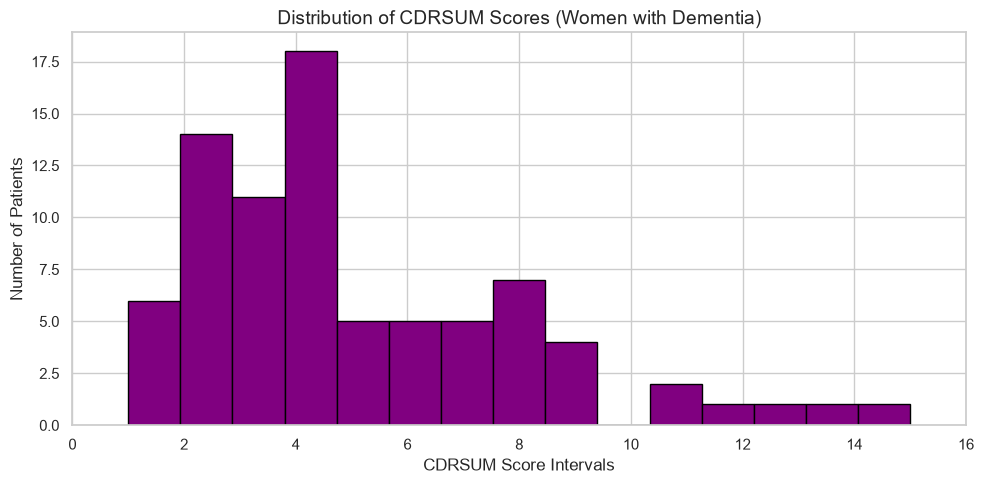

In [431]:
import pandas as pd
import matplotlib.pyplot as plt

df_dementia_women = df_clinical[(df_clinical['NACCUDSD'] == 4.0) & (df_clinical['SEX'] == 2)]

print(f"--- CDRSUM Distribution for Women with Dementia (N={len(df_dementia_women)}) ---")
counts = df_dementia_women['CDRSUM'].value_counts(bins=10).sort_index()
percs = df_dementia_women['CDRSUM'].value_counts(bins=10, normalize=True).sort_index() * 100

summary_df = pd.DataFrame({'Frequency': counts, 'Percentage (%)': percs})
display(summary_df.round(2))

plt.figure(figsize=(10, 5))

plt.hist(
    df_dementia_women['CDRSUM'].dropna(), 
    bins=15, 
    color='purple',
    edgecolor='black'
)

plt.title('Distribution of CDRSUM Scores (Women with Dementia)', fontsize=14)
plt.xlabel('CDRSUM Score Intervals', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)

plt.xticks(range(0, int(df_dementia_women['CDRSUM'].max()) + 2, 2))

plt.tight_layout()
plt.show()

--- CDRSUM Distribution for Men with Dementia (N=50) ---


,Frequency,Percentage (%)
"(0.991, 1.8]",7,14.0
"(1.8, 2.6]",5,10.0
"(2.6, 3.4]",6,12.0
"(3.4, 4.2]",9,18.0
"(4.2, 5.0]",13,26.0
"(5.0, 5.8]",2,4.0
"(5.8, 6.6]",5,10.0
"(6.6, 7.4]",0,0.0
"(7.4, 8.2]",2,4.0
"(8.2, 9.0]",1,2.0


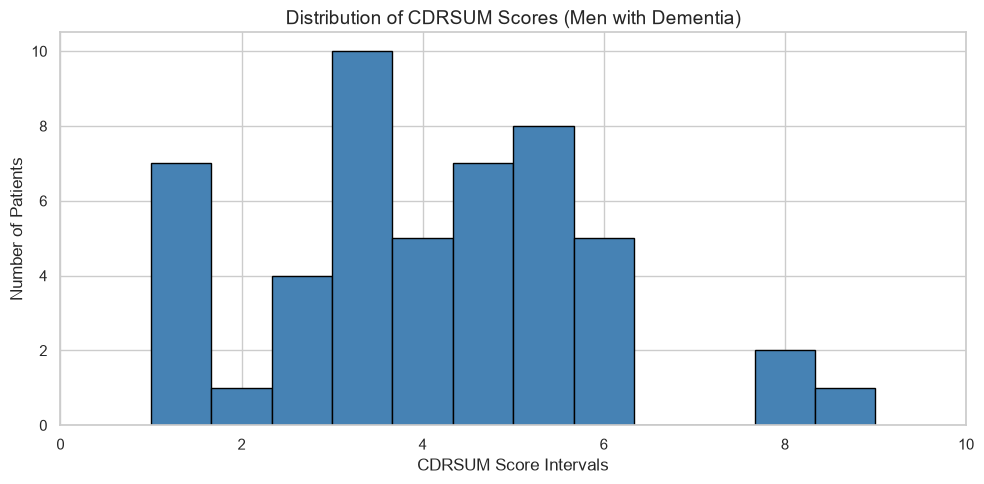

In [432]:
import pandas as pd
import matplotlib.pyplot as plt

df_dementia_men = df_clinical[(df_clinical['NACCUDSD'] == 4.0) & (df_clinical['SEX'] == 1)]

print(f"--- CDRSUM Distribution for Men with Dementia (N={len(df_dementia_men)}) ---")
counts = df_dementia_men['CDRSUM'].value_counts(bins=10).sort_index()
percs = df_dementia_men['CDRSUM'].value_counts(bins=10, normalize=True).sort_index() * 100

summary_df = pd.DataFrame({'Frequency': counts, 'Percentage (%)': percs})
display(summary_df.round(2))

plt.figure(figsize=(10, 5))

plt.hist(
    df_dementia_men['CDRSUM'].dropna(), 
    bins=12, 
    color='steelblue', 
    edgecolor='black'
)

plt.title('Distribution of CDRSUM Scores (Men with Dementia)', fontsize=14)
plt.xlabel('CDRSUM Score Intervals', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)

plt.xticks(range(0, int(df_dementia_men['CDRSUM'].max()) + 2, 2))

plt.tight_layout()
plt.show()

In [433]:
import pandas as pd
import numpy as np

categorical_vars = [
    'SEX', 'HYPERTEN', 'DIABETES', 'CBSTROKE', 'TOBAC100', 
    'DIABTYPE', 'NACCAPOE', 'NACCUDSD', 'CDRGLOB'
]

quant_clinical_vars = [
    'NACCAGE', 'EDUC', 'CDRSUM', 'NACCBMI', 'NACCGDS', 'SMOKYRS'
]

quant_mri_vars = [
    'LH_ENTORHINAL_GVOL', 'RH_ENTORHINAL_GVOL', 
    'LH_PARAHIPPOCAMPAL_GVOL', 'RH_PARAHIPPOCAMPAL_GVOL',
    'LH_ENTORHINAL_AVGTH', 'RH_ENTORHINAL_AVGTH', 
    'LH_PARAHIPPOCAMPAL_AVGTH', 'RH_PARAHIPPOCAMPAL_AVGTH'
]

df_clinical['EDUC'] = df_clinical['EDUC'].replace({99.0: np.nan})
df_clinical['SMOKYRS'] = df_clinical['SMOKYRS'].replace({88.0: np.nan, 99.0: np.nan, 888.0: np.nan})

df_clinical['NACCBMI'] = df_clinical['NACCBMI'].where(
    (df_clinical['NACCBMI'] >= 10) & (df_clinical['NACCBMI'] <= 100)
)
df_clinical['NACCGDS'] = df_clinical['NACCGDS'].where(
    (df_clinical['NACCGDS'] >= 0) & (df_clinical['NACCGDS'] <= 15)
)

for col in categorical_vars:
    if col != 'CDRGLOB':
        df_clinical[col] = df_clinical[col].apply(
            lambda x: np.nan if pd.notnull(x) and x % 1 != 0 else x
        )
    
    if col in ['HYPERTEN', 'DIABETES', 'CBSTROKE', 'TOBAC100', 'NACCAPOE', 'DIABTYPE']:
        df_clinical[col] = df_clinical[col].replace({9.0: np.nan})

print("="*60)
print(" Q6: EMPIRICAL DISTRIBUTIONS AND FREQUENCY TABLES (CLEANED) ")
print("="*60)

print("\n[1] CATEGORICAL VARIABLES (Frequencies & Percentages)")
print("-" * 60)
for col in categorical_vars:
    counts = df_clinical[col].value_counts(dropna=False).sort_index(na_position='last')
    percs = df_clinical[col].value_counts(normalize=True, dropna=False).sort_index(na_position='last') * 100
    
    summary_df = pd.DataFrame({'Frequency (N)': counts, 'Percentage (%)': percs})
    print(f"\nVariable: {col}")
    display(summary_df.round(2))

print("\n[2] QUANTITATIVE VARIABLES: CLINICAL (Distribution Summary)")
print("-" * 60)
display(df_clinical[quant_clinical_vars].describe().round(2).T)

print("\n[3] QUANTITATIVE VARIABLES: STRUCTURAL MRI (Distribution Summary)")
print("-" * 60)
display(df_mri[quant_mri_vars].describe().round(2).T)

 Q6: EMPIRICAL DISTRIBUTIONS AND FREQUENCY TABLES (CLEANED) 

[1] CATEGORICAL VARIABLES (Frequencies & Percentages)
------------------------------------------------------------

Variable: SEX


,Frequency (N),Percentage (%)
SEX,,
1.0,497,40.18
2.0,740,59.82



Variable: HYPERTEN


,Frequency (N),Percentage (%)
HYPERTEN,,
0.0,731,59.09
1.0,444,35.89
2.0,29,2.34
NaN,33,2.67



Variable: DIABETES


,Frequency (N),Percentage (%)
DIABETES,,
0.0,1092,88.28
1.0,112,9.05
2.0,13,1.05
NaN,20,1.62


... (12 outputs left out)


[2] QUANTITATIVE VARIABLES: CLINICAL (Distribution Summary)
------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
NACCAGE,1237.0,68.19,8.04,41.0,63.0,68.0,74.0,91.0
EDUC,1235.0,16.26,2.72,0.0,14.0,16.0,18.0,25.0
CDRSUM,1237.0,0.82,1.72,0.0,0.0,0.0,1.0,15.0
NACCBMI,1106.0,27.33,5.16,15.6,23.6,26.4,30.1,52.4
NACCGDS,1231.0,1.65,2.13,0.0,0.0,1.0,2.0,14.0
SMOKYRS,1215.0,6.23,11.52,0.0,0.0,0.0,9.2,60.0



[3] QUANTITATIVE VARIABLES: STRUCTURAL MRI (Distribution Summary)
------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
LH_ENTORHINAL_GVOL,1237.0,1554.28,413.52,0.00,1295.00,1545.00,1785.00,4265.00
RH_ENTORHINAL_GVOL,1237.0,1525.40,405.44,6.00,1289.00,1513.00,1748.00,5334.00
LH_PARAHIPPOCAMPAL_GVOL,1237.0,2036.71,387.89,167.00,1791.00,2019.00,2257.00,5136.00
RH_PARAHIPPOCAMPAL_GVOL,1237.0,1911.24,344.96,74.00,1718.00,1903.00,2090.00,6335.00
LH_ENTORHINAL_AVGTH,1237.0,2.97,0.38,0.88,2.76,3.02,3.23,3.98
RH_ENTORHINAL_AVGTH,1237.0,3.06,0.40,0.73,2.85,3.10,3.32,3.97
LH_PARAHIPPOCAMPAL_AVGTH,1237.0,2.59,0.28,1.43,2.41,2.59,2.80,3.46
RH_PARAHIPPOCAMPAL_AVGTH,1237.0,2.56,0.25,0.80,2.40,2.56,2.72,3.30


In [434]:
import pandas as pd
import numpy as np

quant_clinical_vars = [
    'NACCAGE', 'EDUC', 'CDRSUM', 'NACCBMI', 'NACCGDS', 'SMOKYRS'
]

quant_mri_vars = [
    'LH_ENTORHINAL_GVOL', 'RH_ENTORHINAL_GVOL', 
    'LH_PARAHIPPOCAMPAL_GVOL', 'RH_PARAHIPPOCAMPAL_GVOL',
    'LH_ENTORHINAL_AVGTH', 'RH_ENTORHINAL_AVGTH', 
    'LH_PARAHIPPOCAMPAL_AVGTH', 'RH_PARAHIPPOCAMPAL_AVGTH'
]

df_clinical['EDUC'] = df_clinical['EDUC'].replace({99.0: np.nan})
df_clinical['SMOKYRS'] = df_clinical['SMOKYRS'].replace({88.0: np.nan, 99.0: np.nan, 888.0: np.nan})

df_clinical['NACCBMI'] = df_clinical['NACCBMI'].where(
    (df_clinical['NACCBMI'] >= 10) & (df_clinical['NACCBMI'] <= 100)
)
df_clinical['NACCGDS'] = df_clinical['NACCGDS'].where(
    (df_clinical['NACCGDS'] >= 0) & (df_clinical['NACCGDS'] <= 15)
)

def calculate_q7_metrics(df, variables):
    stats = []
    for col in variables:
        series = df[col].dropna()
        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        
        stats.append({
            'Variable': col,
            'Mean': series.mean(),
            'Median': series.median(),
            'Std Dev': series.std(),
            'Q1 (25th)': q1,
            'Q3 (75th)': q3,
            'IQR': q3 - q1
        })
    return pd.DataFrame(stats).round(2).set_index('Variable')

print("="*60)
print(" Q7: CENTER AND DISPERSION METRICS (CLEANED DATA) ")
print("="*60)

print("\n[1] CLINICAL VARIABLES")
display(calculate_q7_metrics(df_clinical, quant_clinical_vars))

print("\n[2] STRUCTURAL MRI VARIABLES")
display(calculate_q7_metrics(df_mri, quant_mri_vars))

 Q7: CENTER AND DISPERSION METRICS (CLEANED DATA) 

[1] CLINICAL VARIABLES


,Mean,Median,Std Dev,Q1 (25th),Q3 (75th),IQR
Variable,,,,,,
NACCAGE,68.19,68.0,8.04,63.0,74.0,11.0
EDUC,16.26,16.0,2.72,14.0,18.0,4.0
CDRSUM,0.82,0.0,1.72,0.0,1.0,1.0
NACCBMI,27.33,26.4,5.16,23.6,30.1,6.5
NACCGDS,1.65,1.0,2.13,0.0,2.0,2.0
SMOKYRS,6.23,0.0,11.52,0.0,9.2,9.2



[2] STRUCTURAL MRI VARIABLES


,Mean,Median,Std Dev,Q1 (25th),Q3 (75th),IQR
Variable,,,,,,
LH_ENTORHINAL_GVOL,1554.28,1545.00,413.52,1295.00,1785.00,490.00
RH_ENTORHINAL_GVOL,1525.40,1513.00,405.44,1289.00,1748.00,459.00
LH_PARAHIPPOCAMPAL_GVOL,2036.71,2019.00,387.89,1791.00,2257.00,466.00
RH_PARAHIPPOCAMPAL_GVOL,1911.24,1903.00,344.96,1718.00,2090.00,372.00
LH_ENTORHINAL_AVGTH,2.97,3.02,0.38,2.76,3.23,0.47
RH_ENTORHINAL_AVGTH,3.06,3.10,0.40,2.85,3.32,0.47
LH_PARAHIPPOCAMPAL_AVGTH,2.59,2.59,0.28,2.41,2.80,0.39
RH_PARAHIPPOCAMPAL_AVGTH,2.56,2.56,0.25,2.40,2.72,0.32


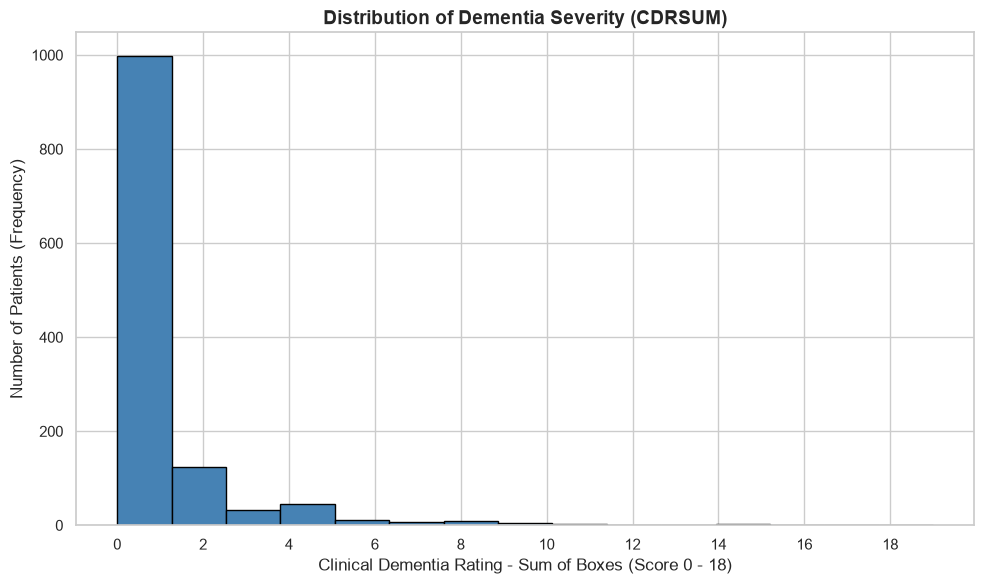

In [435]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

uds = pd.read_csv('../../udslong_imputed.csv')

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

plt.hist(
    uds['CDRSUM'].dropna(), 
    bins=15, 
    range=(0, 19), 
    color='steelblue', 
    edgecolor='black'
)

plt.title('Distribution of Dementia Severity (CDRSUM)', fontsize=14, fontweight='bold')
plt.xlabel('Clinical Dementia Rating - Sum of Boxes (Score 0 - 18)', fontsize=12)
plt.ylabel('Number of Patients (Frequency)', fontsize=12)

plt.xticks(range(0, 19, 2))

plt.tight_layout()
plt.show()

C:\Users\lotus\AppData\Local\Temp\ipykernel_7312\1586670765.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


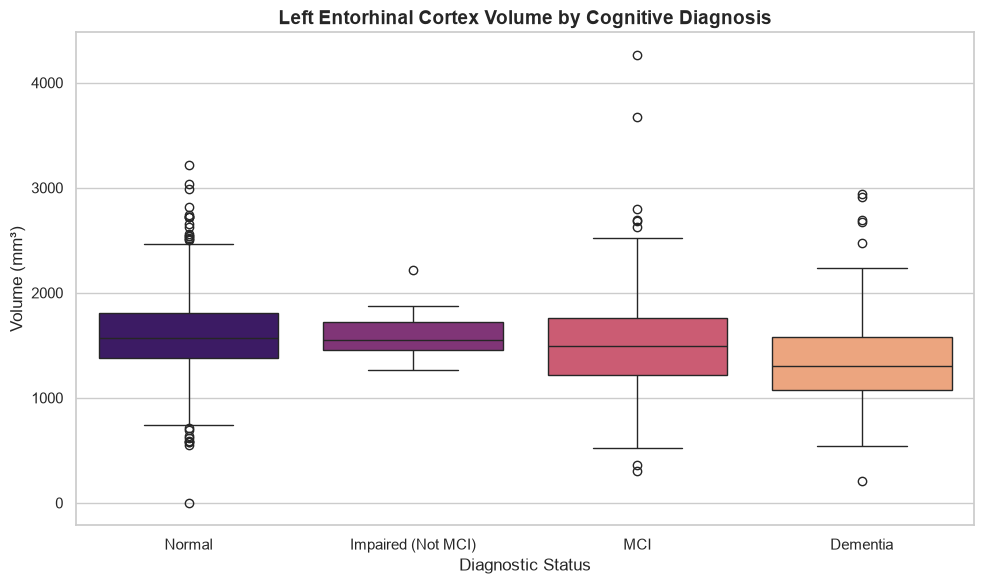

In [436]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

uds = pd.read_csv('../../udslong_imputed.csv')
mri = pd.read_csv('../../mriscanclean.csv')

merged_df = pd.merge(
    uds[['NACCID', 'NACCUDSD']], 
    mri[['NACCID', 'LH_ENTORHINAL_GVOL']], 
    on='NACCID'
)

merged_df['Diagnosis'] = merged_df['NACCUDSD'].replace({
    1.0: 'Normal', 
    2.0: 'Impaired (Not MCI)', 
    3.0: 'MCI', 
    4.0: 'Dementia'
})

plot_df = merged_df.dropna()
category_order = ['Normal', 'Impaired (Not MCI)', 'MCI', 'Dementia']

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=plot_df, 
    x='Diagnosis', 
    y='LH_ENTORHINAL_GVOL', 
    order=category_order,
    palette='magma'
)

plt.title('Left Entorhinal Cortex Volume by Cognitive Diagnosis', fontsize=14, fontweight='bold')
plt.xlabel('Diagnostic Status', fontsize=12)
plt.ylabel('Volume (mm³)', fontsize=12)

plt.tight_layout()
plt.show()

C:\Users\lotus\AppData\Local\Temp\ipykernel_7312\4070933481.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


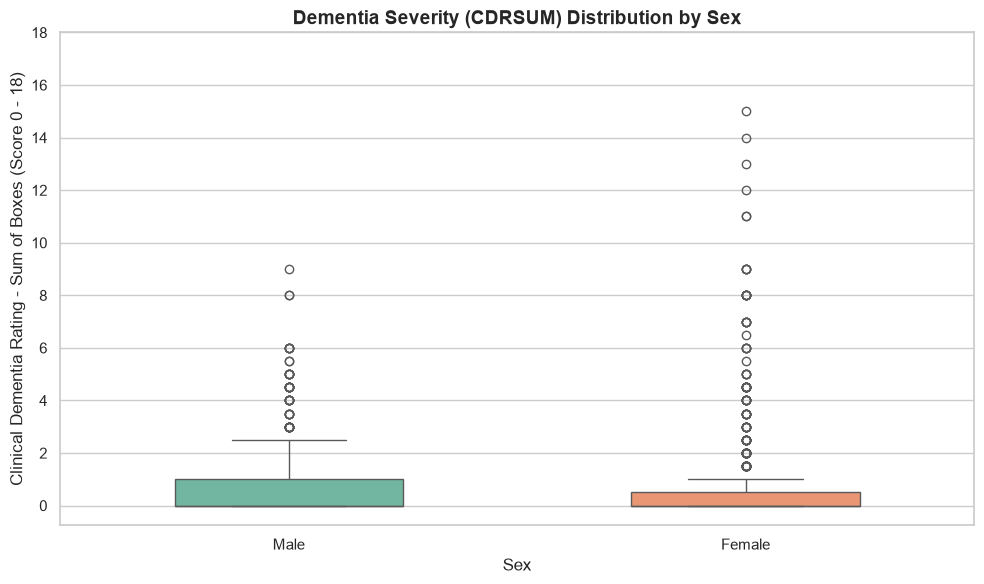

In [437]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

uds = pd.read_csv('../../udslong_imputed.csv')

plot_df = uds[['SEX', 'CDRSUM']].copy().dropna()
plot_df['Sex'] = plot_df['SEX'].replace({1.0: 'Male', 2.0: 'Female'})

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=plot_df, 
    x='Sex', 
    y='CDRSUM', 
    palette='Set2',
    width=0.5
)

plt.title('Dementia Severity (CDRSUM) Distribution by Sex', fontsize=14, fontweight='bold')
plt.xlabel('Sex', fontsize=12)
plt.ylabel('Clinical Dementia Rating - Sum of Boxes (Score 0 - 18)', fontsize=12)
plt.yticks(range(0, 19, 2))

plt.tight_layout()
plt.show()

C:\Users\lotus\AppData\Local\Temp\ipykernel_7312\621236651.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


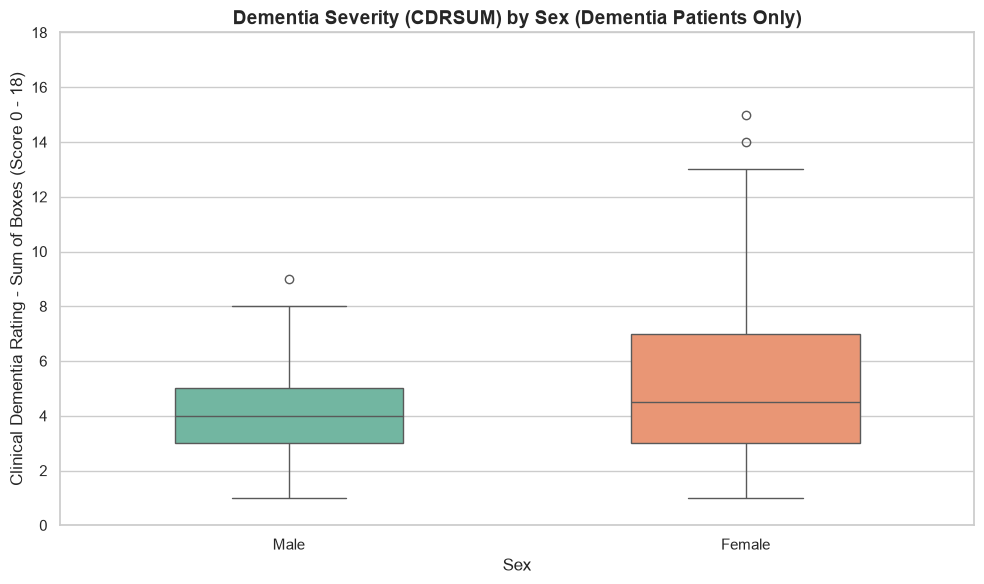

In [438]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

uds = pd.read_csv('../../udslong_imputed.csv')

uds_dementia = uds[uds['NACCUDSD'] == 4.0].copy()

uds_dementia['Sex'] = uds_dementia['SEX'].replace({1.0: 'Male', 2.0: 'Female'})

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=uds_dementia, 
    x='Sex', 
    y='CDRSUM', 
    palette='Set2',
    width=0.5
)

plt.title('Dementia Severity (CDRSUM) by Sex (Dementia Patients Only)', fontsize=14, fontweight='bold')
plt.xlabel('Sex', fontsize=12)
plt.ylabel('Clinical Dementia Rating - Sum of Boxes (Score 0 - 18)', fontsize=12)
plt.yticks(range(0, 19, 2))

plt.tight_layout()
plt.show()

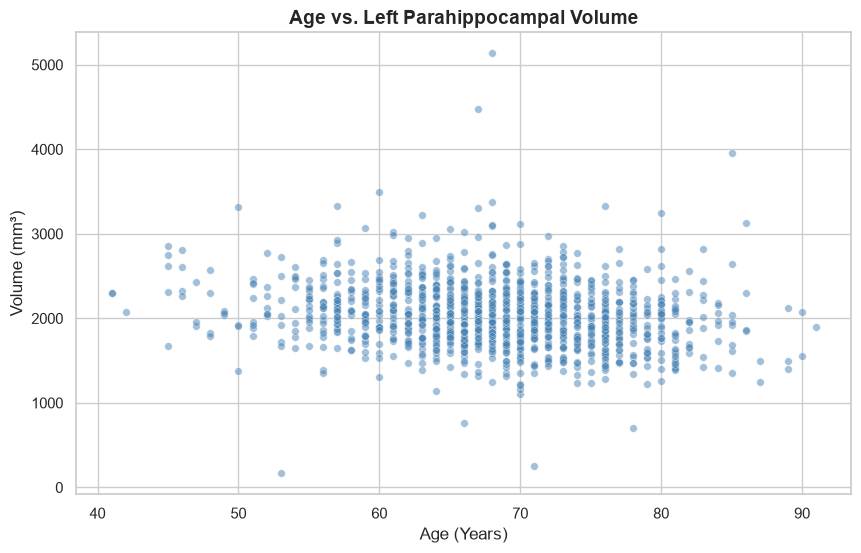

In [439]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

uds = pd.read_csv('../../udslong_imputed.csv')
mri = pd.read_csv('../../mriscanclean.csv')

merged_df = pd.merge(
    uds[['NACCID', 'NACCAGE']], 
    mri[['NACCID', 'LH_PARAHIPPOCAMPAL_GVOL']], 
    on='NACCID'
)

plot_df = merged_df.dropna()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df, 
    x='NACCAGE', 
    y='LH_PARAHIPPOCAMPAL_GVOL', 
    alpha=0.5, 
    color='steelblue', 
    s=30
)

plt.title('Age vs. Left Parahippocampal Volume', fontsize=14, fontweight='bold')
plt.xlabel('Age (Years)', fontsize=12)
plt.ylabel('Volume (mm³)', fontsize=12)

plt.show()

In [440]:
import pandas as pd

# 1. Load the data directly from the files
uds = pd.read_csv('../../udslong_imputed.csv')
mri = pd.read_csv('../../mriscanclean.csv')

# 2. Add categorical labels to the clinical data
uds['Diagnosis_Label'] = uds['NACCUDSD'].replace({
    1.0: 'Normal', 2.0: 'Impaired (Not MCI)', 3.0: 'MCI', 4.0: 'Dementia'
})
uds['Sex_Label'] = uds['SEX'].replace({
    1.0: 'Male', 2.0: 'Female'
})

def descriptive_summary(x):
    return pd.Series({
        'Count': x.count(),
        'Mean': x.mean(),
        'Median': x.median(),
        'Std Dev': x.std(),
        'IQR': x.quantile(0.75) - x.quantile(0.25)
    })

print("="*70)
print(" Q9: PURELY DESCRIPTIVE COMPARISONS ")
print("="*70)

# 3. CORRECTED: Merge securely on 'NACCID' to prevent data corruption
merged_df = pd.merge(
    uds[['NACCID', 'Diagnosis_Label']], 
    mri[['NACCID', 'LH_ENTORHINAL_GVOL']], 
    on='NACCID'
)

print("\n[1] Left Entorhinal Cortex Volume by Cognitive Diagnosis")
vol_comparison = merged_df.groupby('Diagnosis_Label')['LH_ENTORHINAL_GVOL'].apply(descriptive_summary).unstack()
vol_comparison = vol_comparison.reindex(['Normal', 'Impaired (Not MCI)', 'MCI', 'Dementia'])
display(vol_comparison.round(2))

print("\n[2] Dementia Severity (CDRSUM) by Sex")
severity_comparison = uds.groupby('Sex_Label')['CDRSUM'].apply(descriptive_summary).unstack()
display(severity_comparison.round(2))

 Q9: PURELY DESCRIPTIVE COMPARISONS 

[1] Left Entorhinal Cortex Volume by Cognitive Diagnosis


C:\Users\lotus\AppData\Local\Temp\ipykernel_7312\2530424865.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  uds['Diagnosis_Label'] = uds['NACCUDSD'].replace({
C:\Users\lotus\AppData\Local\Temp\ipykernel_7312\2530424865.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  uds['Sex_Label'] = uds['SEX'].replace({


,Count,Mean,Median,Std Dev,IQR
Diagnosis_Label,,,,,
Normal,847.0,1595.26,1573.0,369.48,436.0
Impaired (Not MCI),7.0,1628.29,1554.0,318.46,265.0
MCI,252.0,1512.68,1496.5,494.54,542.0
Dementia,131.0,1365.37,1305.0,458.25,509.0



[2] Dementia Severity (CDRSUM) by Sex


,Count,Mean,Median,Std Dev,IQR
Sex_Label,,,,,
Female,740.0,0.80,0.0,1.89,0.5
Male,497.0,0.85,0.0,1.44,1.0


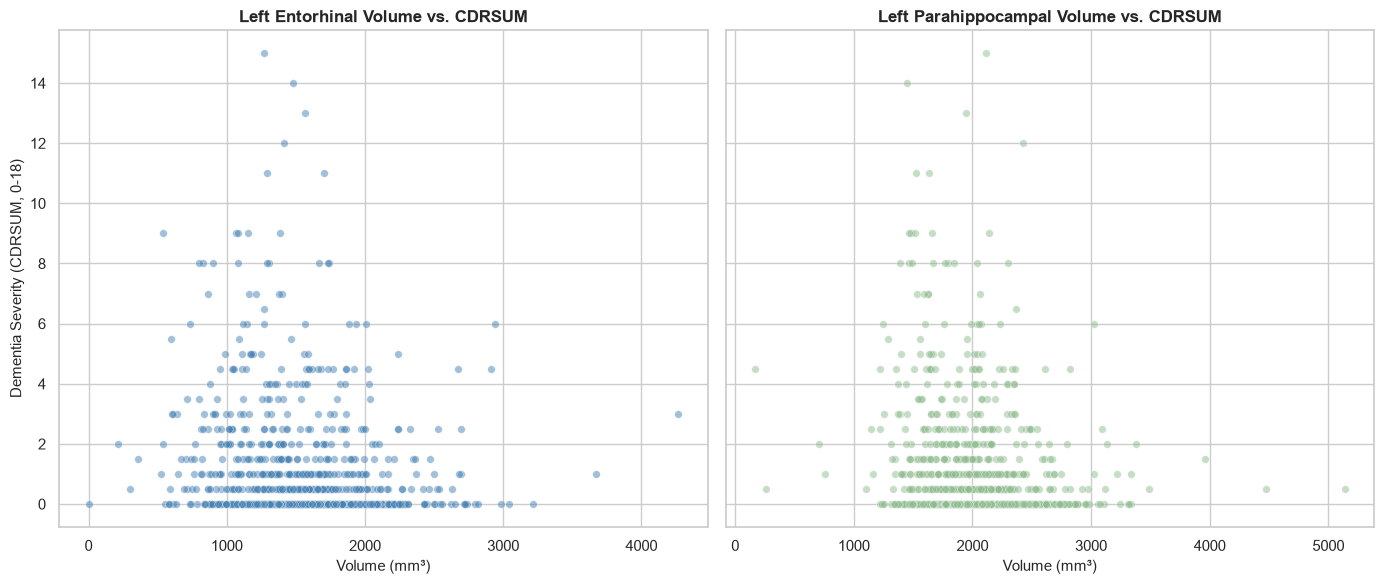

In [441]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

uds = pd.read_csv('../../udslong_imputed.csv')
mri = pd.read_csv('../../mriscanclean.csv')

merged_df = pd.merge(
    uds[['NACCID', 'CDRSUM']], 
    mri[['NACCID', 'LH_ENTORHINAL_GVOL', 'LH_PARAHIPPOCAMPAL_GVOL']], 
    on='NACCID'
)

plot_df = merged_df.dropna()

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

sns.scatterplot(
    ax=axes[0], data=plot_df, 
    x='LH_ENTORHINAL_GVOL', y='CDRSUM', 
    alpha=0.5, color='steelblue', s=30
)
axes[0].set_title('Left Entorhinal Volume vs. CDRSUM', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Volume (mm³)', fontsize=11)
axes[0].set_ylabel('Dementia Severity (CDRSUM, 0-18)', fontsize=11)
axes[0].set_yticks(range(0, 19, 2))

sns.scatterplot(
    ax=axes[1], data=plot_df, 
    x='LH_PARAHIPPOCAMPAL_GVOL', y='CDRSUM', 
    alpha=0.5, color='darkseagreen', s=30
)
axes[1].set_title('Left Parahippocampal Volume vs. CDRSUM', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Volume (mm³)', fontsize=11)

plt.tight_layout()
plt.show()

C:\Users\lotus\AppData\Local\Temp\ipykernel_7312\3701417803.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


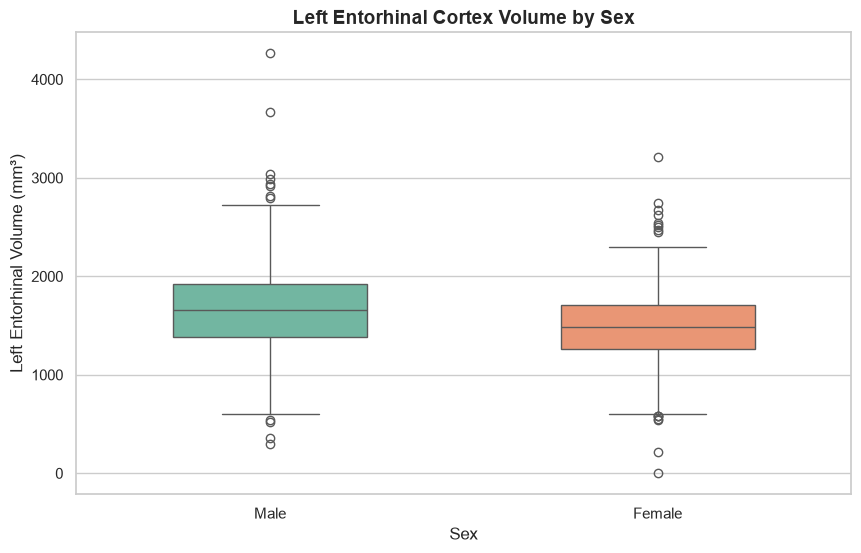

In [442]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

uds = pd.read_csv('../../udslong_imputed.csv')
mri = pd.read_csv('../../mriscanclean.csv')

merged_df = pd.merge(
    uds[['NACCID', 'SEX']], 
    mri[['NACCID', 'LH_ENTORHINAL_GVOL']], 
    on='NACCID'
)

merged_df['Sex'] = merged_df['SEX'].replace({1.0: 'Male', 2.0: 'Female'})
plot_df = merged_df.dropna()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=plot_df, 
    x='Sex', 
    y='LH_ENTORHINAL_GVOL', 
    palette='Set2',
    width=0.5
)

plt.title('Left Entorhinal Cortex Volume by Sex', fontsize=14, fontweight='bold')
plt.xlabel('Sex', fontsize=12)
plt.ylabel('Left Entorhinal Volume (mm³)', fontsize=12)

plt.show()

C:\Users\lotus\AppData\Local\Temp\ipykernel_7312\3136648897.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  uds['MOCATOTS_clean'] = uds['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)


MOCATOTS Summary Statistics:
count    1228.000000
mean       24.392997
std         4.424823
min         0.000000
25%        23.000000
50%        25.400000
75%        27.000000
max        30.000000
Name: MOCATOTS_clean, dtype: float64
Missing Values (NaN): 9


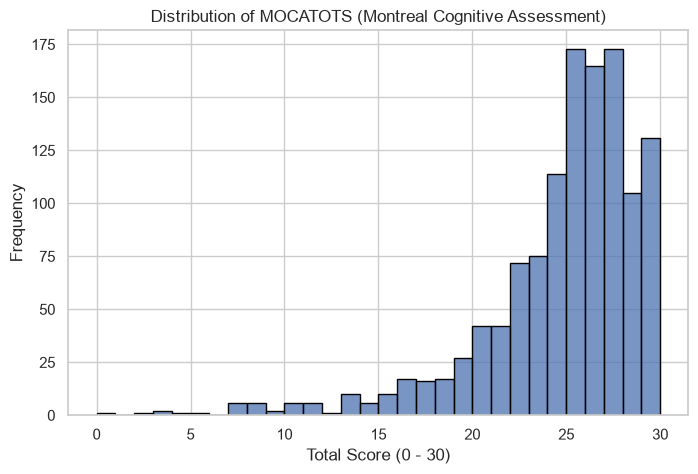

In [443]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

uds = pd.read_csv('../../udslong_imputed.csv')

uds['MOCATOTS_clean'] = uds['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)
uds.loc[uds['MOCATOTS_clean'] > 30, 'MOCATOTS_clean'] = np.nan 

stats = uds['MOCATOTS_clean'].describe()
print("MOCATOTS Summary Statistics:")
print(stats[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']])
print(f"Missing Values (NaN): {uds['MOCATOTS_clean'].isna().sum()}")

plt.figure(figsize=(8, 5))
sns.histplot(uds['MOCATOTS_clean'].dropna(), bins=30, edgecolor='black') 
plt.title('Distribution of MOCATOTS (Montreal Cognitive Assessment)')
plt.xlabel('Total Score (0 - 30)')
plt.ylabel('Frequency')
plt.show()

In [444]:
import pandas as pd
import numpy as np

# 1. Load the datasets
uds = pd.read_csv('../../udslong_imputed.csv')
mri = pd.read_csv('../../mriscanclean.csv')

merged_df = pd.merge(
    uds[['NACCID', 'SEX']], 
    mri[['NACCID', 'LH_ENTORHINAL_GVOL']], 
    on='NACCID'
)

def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

stats_by_sex = merged_df.groupby('SEX')['LH_ENTORHINAL_GVOL'].agg(
    Count='count',
    Mean=lambda x: round(x.mean(), 2),
    Median='median',
    Std_Dev=lambda x: round(x.std(), 2),
    IQR=iqr
).reset_index()

stats_by_sex['SEX'] = stats_by_sex['SEX'].map({1.0: 'Male', 2.0: 'Female'})

print(stats_by_sex.to_string(index=False))

   SEX  Count    Mean  Median  Std_Dev    IQR
  Male    497 1665.74  1653.0   460.35 538.00
Female    740 1479.41  1482.0   360.28 445.75


In [445]:
import pandas as pd


clinical_var_count = len(pd.read_csv('../../udslong_imputed.csv').columns)
mri_var_count = len(pd.read_csv('../../mriscanclean.csv').columns)

print(f"Total variables in udslong_imputed (Clinical): {clinical_var_count}")
print(f"Total variables in mriscanclean (MRI): {mri_var_count}")



Total variables in udslong_imputed (Clinical): 180
Total variables in mriscanclean (MRI): 126


In [446]:
import pandas as pd

uds = pd.read_csv('../../mriscanclean.csv')

unique_participants = uds['NACCID'].nunique()
total_visits = len(uds)
visits_distribution = uds['NACCID'].value_counts().value_counts()

print(f"Total Unique Participants: {unique_participants}")
print(f"Total Visits: {total_visits}")
print("Distribution of Visits per Participant:")
print(visits_distribution)

Total Unique Participants: 1237
Total Visits: 1237
Distribution of Visits per Participant:
count
1    1237
Name: count, dtype: int64


In [447]:
import pandas as pd

uds_df = pd.read_csv('../../udslong_imputed.csv')
mri_df = pd.read_csv('../../mriscanclean.csv')

if 'NACCUDSD' in mri_df.columns:
    mri_df = mri_df.drop(columns=['NACCUDSD'])

print(f"Total individuals in UDS file: {len(uds_df)}")
print(f"Total individuals in MRI file: {len(mri_df)}")

merged_df = pd.merge(uds_df, mri_df, on='NACCID', how='outer', indicator=True)

common_cases = len(merged_df[merged_df['_merge'] == 'both'])
uds_only = len(merged_df[merged_df['_merge'] == 'left_only'])
mri_only = len(merged_df[merged_df['_merge'] == 'right_only'])

print(f"Common individuals (Matched): {common_cases}")
print(f"Unmatched (UDS only): {uds_only}")
print(f"Unmatched (MRI only): {mri_only}")
print(f"Final multimodal sample size: {common_cases}")

final_multimodal_df = merged_df[merged_df['_merge'] == 'both'].drop(columns=['_merge'])

final_multimodal_df.to_csv('multimodal_merged_dataset.csv', index=False)
print("Merged file saved successfully as 'multimodal_merged_dataset.csv'")

Total individuals in UDS file: 1237
Total individuals in MRI file: 1237
Common individuals (Matched): 1237
Unmatched (UDS only): 0
Unmatched (MRI only): 0
Final multimodal sample size: 1237
Merged file saved successfully as 'multimodal_merged_dataset.csv'


C:\Users\lotus\AppData\Local\Temp\ipykernel_7312\461726113.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df = pd.merge(uds_df, mri_df, on='NACCID', how='outer', indicator=True)
C:\Users\lotus\AppData\Local\Temp\ipykernel_7312\461726113.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df = pd.merge(uds_df, mri_df, on='NACCID', how='outer', indicator=True)
C:\Users\lotus\AppData\Local\Temp\ipykernel_7312\461726113.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of cal

In [448]:
import pandas as pd



var_count = len(pd.read_csv('../../multimodal_merged_dataset.csv').columns)

print(f"Total variables in multimodal merged dataset: {var_count}")




Total variables in multimodal merged dataset: 304


In [449]:
import pandas as pd
import numpy as np

uds_df = pd.read_csv('../../udslong_imputed.csv')
mri_df = pd.read_csv('../../mriscanclean.csv')

if 'NACCUDSD' in mri_df.columns:
    mri_df = mri_df.drop(columns=['NACCUDSD'])

df = pd.merge(uds_df, mri_df, on='NACCID', how='outer', indicator=True)

uds_continuous = ['CDRSUM', 'NACCAGE', 'NACCBMI']
uds_discrete   = ['EDUC', 'NACCGDS', 'SMOKYRS', 'MOCATOTS']
uds_ordinal    = ['NACCUDSD', 'CDRGLOB']
uds_nominal    = ['NACCAPOE', 'HYPERTEN', 'DIABETES', 'DIABTYPE', 'CBSTROKE']
uds_binary     = ['SEX', 'TOBAC100']

main_uds_vars = uds_continuous + uds_discrete + uds_ordinal + uds_nominal + uds_binary

main_mri_vars = [
    'LH_ENTORHINAL_GVOL', 'RH_ENTORHINAL_GVOL',
    'LH_PARAHIPPOCAMPAL_GVOL', 'RH_PARAHIPPOCAMPAL_GVOL',
    'LH_ENTORHINAL_AVGTH', 'RH_ENTORHINAL_AVGTH',
    'LH_PARAHIPPOCAMPAL_AVGTH', 'RH_PARAHIPPOCAMPAL_AVGTH'
]

all_main_vars = main_uds_vars + main_mri_vars
print(f"Total main variables audited: {len(all_main_vars)} (UDS: {len(main_uds_vars)}, MRI: {len(main_mri_vars)})")

raw_missing_count = df[all_main_vars].isnull().sum()
raw_missing_pct = (raw_missing_count / len(df)) * 100

audit_df = df.copy()

exact_dups = audit_df.duplicated().sum()
id_dups = audit_df.duplicated(subset=['NACCID']).sum()
print(f"Duplicate check -> Exact duplicate rows: {exact_dups}, Duplicate NACCIDs: {id_dups}")
audit_df = audit_df.drop_duplicates().drop_duplicates(subset=['NACCID'], keep='first')

audit_df[all_main_vars] = audit_df[all_main_vars].replace(-4, np.nan)

cat_vars = uds_nominal + uds_binary + ['NACCUDSD']
for col in cat_vars:
    audit_df.loc[audit_df[col].isin([8, 9, 88, 99]), col] = np.nan
    not_null = audit_df[col].notnull()
    audit_df.loc[not_null & ((audit_df[col] % 1 != 0) | (audit_df[col] < 0)), col] = np.nan

audit_df.loc[~audit_df['SEX'].isin([1, 2]), 'SEX'] = np.nan
audit_df.loc[~audit_df['NACCUDSD'].isin([1, 2, 3, 4]), 'NACCUDSD'] = np.nan
audit_df.loc[~audit_df['NACCAPOE'].isin([1, 2, 3, 4, 5, 6]), 'NACCAPOE'] = np.nan
audit_df.loc[~audit_df['CDRGLOB'].isin([0.0, 0.5, 1.0, 2.0, 3.0]), 'CDRGLOB'] = np.nan

audit_df.loc[audit_df['EDUC'].isin([88, 99]) | (audit_df['EDUC'] < 0) | (audit_df['EDUC'] > 36), 'EDUC'] = np.nan
audit_df.loc[audit_df['NACCGDS'].isin([88, 99]) | (audit_df['NACCGDS'] < 0) | (audit_df['NACCGDS'] > 15), 'NACCGDS'] = np.nan
audit_df.loc[audit_df['SMOKYRS'].isin([88, 99]) | (audit_df['SMOKYRS'] < 0) | (audit_df['SMOKYRS'] > 100), 'SMOKYRS'] = np.nan
audit_df.loc[audit_df['MOCATOTS'].isin([88, 99]) | (audit_df['MOCATOTS'] < 0) | (audit_df['MOCATOTS'] > 30), 'MOCATOTS'] = np.nan

audit_df.loc[(audit_df['NACCAGE'] <= 0) | (audit_df['NACCAGE'] > 120) | audit_df['NACCAGE'].isin([88, 99, 888, 999]), 'NACCAGE'] = np.nan
audit_df.loc[(audit_df['NACCBMI'] < 10) | (audit_df['NACCBMI'] > 100) | audit_df['NACCBMI'].isin([888, 999, 888.8, 999.9]), 'NACCBMI'] = np.nan
audit_df.loc[(audit_df['CDRSUM'] < 0) | (audit_df['CDRSUM'] > 18) | audit_df['CDRSUM'].isin([88, 99]), 'CDRSUM'] = np.nan

for col in main_mri_vars:
    audit_df.loc[audit_df[col] <= 0, col] = np.nan

inconsistent_educ = (audit_df['EDUC'] > audit_df['NACCAGE'])
inconsistent_smok = (audit_df['SMOKYRS'] > audit_df['NACCAGE'])
print(f"Logical inconsistencies -> EDUC > NACCAGE: {inconsistent_educ.sum()}, SMOKYRS > NACCAGE: {inconsistent_smok.sum()}")
audit_df.loc[inconsistent_educ, 'EDUC'] = np.nan
audit_df.loc[inconsistent_smok, 'SMOKYRS'] = np.nan

post_missing_count = audit_df[all_main_vars].isnull().sum()
post_missing_pct = (post_missing_count / len(audit_df)) * 100

missing_report = pd.DataFrame({
    'Modality': ['UDS']*len(main_uds_vars) + ['MRI']*len(main_mri_vars),
    'Raw_NaN_Count': raw_missing_count,
    'Raw_NaN_%': raw_missing_pct.round(2),
    'Post_Audit_NaN_Count': post_missing_count,
    'Post_Audit_NaN_%': post_missing_pct.round(2)
})

print("\n=== Q4 PART 1: MISSINGNESS REPORT (24 MAIN VARIABLES) ===")
print(missing_report.to_string())

audit_df['Has_Valid_MRI'] = (audit_df['_merge'] == 'both') & (audit_df[main_mri_vars].notnull().all(axis=1))

print("\n=== Q4 PART 2: MULTIMODAL SAMPLE SELECTION CHECK ===")
print(audit_df['Has_Valid_MRI'].value_counts().rename({True: 'Has Complete MRI', False: 'Missing/No MRI'}))

key_comparison_vars = ['NACCAGE', 'EDUC', 'CDRSUM', 'MOCATOTS', 'NACCGDS', 'NACCBMI', 'SEX', 'NACCUDSD']
if audit_df['Has_Valid_MRI'].nunique() > 1:
    print("\nDescriptive Comparison (Mean/SD for continuous, Proportions for categorical):")
    print(audit_df.groupby('Has_Valid_MRI')[key_comparison_vars].describe().T)
else:
    print("\n100% of UDS individuals have valid, matched MRI scans (No non-MRI subset exists).")
    print("Baseline Descriptive Statistics of Key UDS Variables in the Multimodal Cohort (N=1237):")
    summary_stats = audit_df[['NACCAGE', 'EDUC', 'CDRSUM', 'MOCATOTS', 'NACCGDS', 'NACCBMI']].agg(['count', 'mean', 'std', 'median', lambda x: x.quantile(0.75) - x.quantile(0.25)])
    summary_stats.index = ['Valid N', 'Mean', 'SD', 'Median', 'IQR']
    print(summary_stats.round(2).T.to_string())

Total main variables audited: 24 (UDS: 16, MRI: 8)
Duplicate check -> Exact duplicate rows: 0, Duplicate NACCIDs: 0
Logical inconsistencies -> EDUC > NACCAGE: 0, SMOKYRS > NACCAGE: 0

=== Q4 PART 1: MISSINGNESS REPORT (24 MAIN VARIABLES) ===
                         Modality  Raw_NaN_Count  Raw_NaN_%  Post_Audit_NaN_Count  Post_Audit_NaN_%
CDRSUM                        UDS              0        0.0                     0              0.00
NACCAGE                       UDS              0        0.0                     0              0.00
NACCBMI                       UDS              0        0.0                   131             10.59
EDUC                          UDS              0        0.0                     2              0.16
NACCGDS                       UDS              0        0.0                     6              0.49
SMOKYRS                       UDS              0        0.0                    22              1.78
MOCATOTS                      UDS              0        0.

C:\Users\lotus\AppData\Local\Temp\ipykernel_7312\2797323743.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = pd.merge(uds_df, mri_df, on='NACCID', how='outer', indicator=True)
C:\Users\lotus\AppData\Local\Temp\ipykernel_7312\2797323743.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = pd.merge(uds_df, mri_df, on='NACCID', how='outer', indicator=True)
C:\Users\lotus\AppData\Local\Temp\ipykernel_7312\2797323743.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame

=== MOCATOTS (UDS Cognitive Score) ===
Count (N): 1228 | Missing (NaN): 9
Center     -> Mean: 24.39 | Median: 25.40
Dispersion -> Std Dev: 4.42 | Variance: 19.58 | IQR: 4.00 (Q1: 23.00, Q3: 27.00)
Range      -> Min: 0.00 | Max: 30.00 | Range (Max - Min): 30.00
Outliers   -> Lower Bound: 17.00 | Upper Bound: 33.00
  - Low Outliers Count : 76
  - High Outliers Count: 0

=== LH_PARAHIPPOCAMPAL_AVGTH (MRI Cortical Thickness) ===
Count (N): 1237 | Missing (NaN): 0
Center     -> Mean: 2.59 | Median: 2.59
Dispersion -> Std Dev: 0.28 | Variance: 0.08 | IQR: 0.39 (Q1: 2.41, Q3: 2.80)
Range      -> Min: 1.43 | Max: 3.46 | Range (Max - Min): 2.03
Outliers   -> Lower Bound: 1.82 | Upper Bound: 3.38
  - Low Outliers Count : 8
  - High Outliers Count: 2



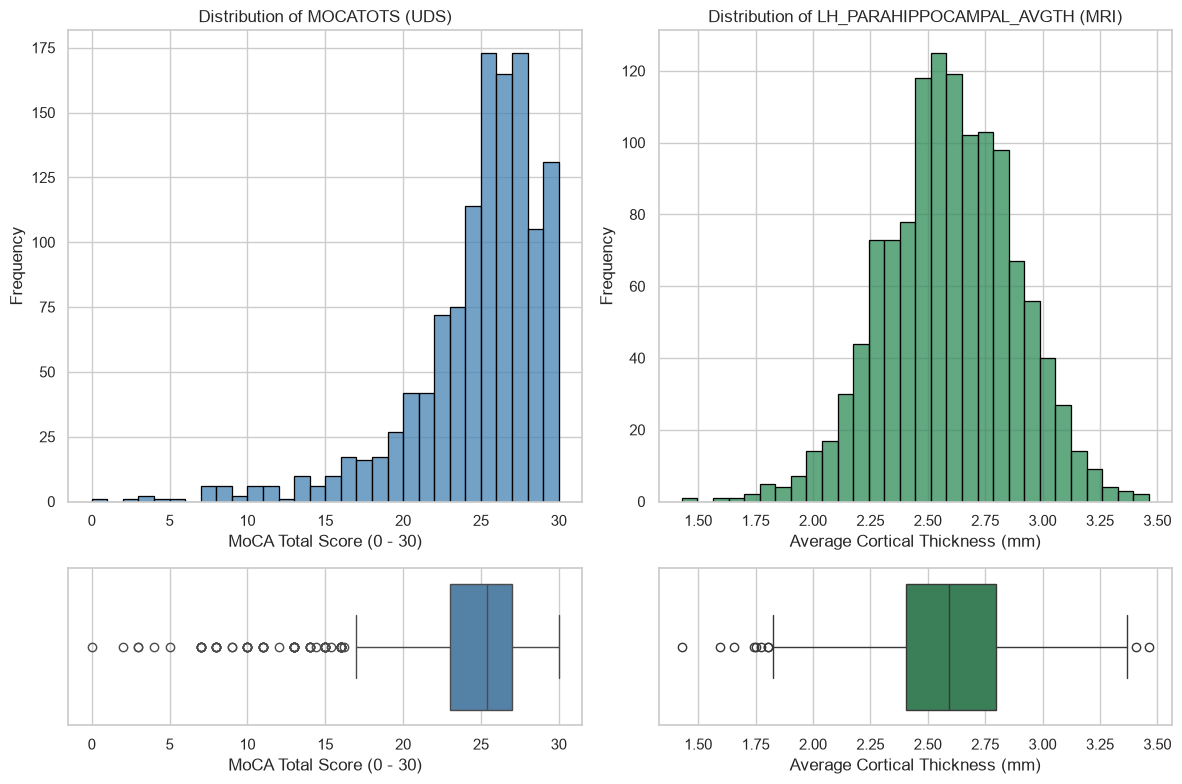

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. بارگذاری فایل‌های داده
uds = pd.read_csv('../../udslong_imputed.csv')
mri = pd.read_csv('../../mriscanclean.csv')

df = pd.merge(
    uds[['NACCID', 'MOCATOTS']], 
    mri[['NACCID', 'LH_PARAHIPPOCAMPAL_AVGTH']], 
    on='NACCID'
)

df['MOCATOTS_clean'] = df['MOCATOTS'].replace([88, 95, 96, 97, 98, 99, -4, 88.0, 99.0, -4.0], np.nan)
df.loc[df['MOCATOTS_clean'] > 30, 'MOCATOTS_clean'] = np.nan

def analyze_distribution(series, var_name):
    s = series.dropna()
    n = len(s)
    missing = series.isna().sum()
    
    mean_val = s.mean()
    median_val = s.median()
    
    std_val = s.std()
    var_val = s.var()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr_val = q3 - q1
    
    min_val = s.min()
    max_val = s.max()
    total_range = max_val - min_val
    
    lower_fence = q1 - 1.5 * iqr_val
    upper_fence = q3 + 1.5 * iqr_val
    low_outliers = s[s < lower_fence]
    high_outliers = s[s > upper_fence]
    
    print(f"=== {var_name} ===")
    print(f"Count (N): {n} | Missing (NaN): {missing}")
    print(f"Center     -> Mean: {mean_val:.2f} | Median: {median_val:.2f}")
    print(f"Dispersion -> Std Dev: {std_val:.2f} | Variance: {var_val:.2f} | IQR: {iqr_val:.2f} (Q1: {q1:.2f}, Q3: {q3:.2f})")
    print(f"Range      -> Min: {min_val:.2f} | Max: {max_val:.2f} | Range (Max - Min): {total_range:.2f}")
    print(f"Outliers   -> Lower Bound: {lower_fence:.2f} | Upper Bound: {upper_fence:.2f}")
    print(f"  - Low Outliers Count : {len(low_outliers)}")
    print(f"  - High Outliers Count: {len(high_outliers)}\n")

analyze_distribution(df['MOCATOTS_clean'], 'MOCATOTS (UDS Cognitive Score)')
analyze_distribution(df['LH_PARAHIPPOCAMPAL_AVGTH'], 'LH_PARAHIPPOCAMPAL_AVGTH (MRI Cortical Thickness)')

fig, axes = plt.subplots(2, 2, figsize=(12, 8), gridspec_kw={'height_ratios': [3, 1]})

sns.histplot(df['MOCATOTS_clean'].dropna(), bins=30, edgecolor='black', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Distribution of MOCATOTS (UDS)')
axes[0, 0].set_xlabel('MoCA Total Score (0 - 30)')
axes[0, 0].set_ylabel('Frequency')

sns.boxplot(x=df['MOCATOTS_clean'].dropna(), ax=axes[1, 0], color='steelblue')
axes[1, 0].set_xlabel('MoCA Total Score (0 - 30)')

sns.histplot(df['LH_PARAHIPPOCAMPAL_AVGTH'].dropna(), bins=30, edgecolor='black', ax=axes[0, 1], color='seagreen')
axes[0, 1].set_title('Distribution of LH_PARAHIPPOCAMPAL_AVGTH (MRI)')
axes[0, 1].set_xlabel('Average Cortical Thickness (mm)')
axes[0, 1].set_ylabel('Frequency')

sns.boxplot(x=df['LH_PARAHIPPOCAMPAL_AVGTH'].dropna(), ax=axes[1, 1], color='seagreen')
axes[1, 1].set_xlabel('Average Cortical Thickness (mm)')

plt.tight_layout()
plt.savefig('joint_moca_lh_parahippo_avgth.png', dpi=300)
plt.show()